# 01 — Flickr8k Data Preparation

Prepares Flickr8k for the CNN (VGG16) + LSTM captioning model using `src/data_preprocessing.py`:

1. load and validate the dataset;
2. clean captions and add `startseq` / `endseq`;
3. split by **image** into train / val / test (80/10/10, seed 42);
4. fit the tokenizer on **training captions only**;
5. build next-word training sequences.

No image pixels or VGG16 features are loaded here — that is the next task.

**Data location:** `data/flickr8k/` containing `Images/` and `captions.txt` (or set the `FLICKR8K_DIR` environment variable). See the README for download steps.

In [1]:
# Make the project root importable whether this runs locally (notebooks/) or in Colab.
import os, sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Google Colab only: uncomment to download Flickr8k (~1 GB) with kagglehub.
# import kagglehub
# os.environ["FLICKR8K_DIR"] = kagglehub.dataset_download("adityajn105/flickr8k")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from src.data_preprocessing import (
    get_dataset_paths, load_captions, clean_caption, prepare_flickr8k,
    create_sequences, OOV_TOKEN,
)

## 1. Load and validate the dataset

In [3]:
images_dir, captions_file = get_dataset_paths()
raw_captions = load_captions(captions_file)

n_files = len(list(images_dir.glob("*.jpg")))
print(f"Image files in Images/ : {n_files:,}")
print(f"Images with captions   : {len(raw_captions):,}")
print(f"Total captions         : {sum(len(c) for c in raw_captions.values()):,}")
print(f"Captions per image     : {sorted({len(c) for c in raw_captions.values()})}")

Image files in Images/ : 8,091
Images with captions   : 8,091
Total captions         : 40,455
Captions per image     : [5]


In [4]:
# One-call pipeline: validate image files, clean, split, fit tokenizer (train only).
data = prepare_flickr8k(seed=42)

## 2. Example image with its reference captions

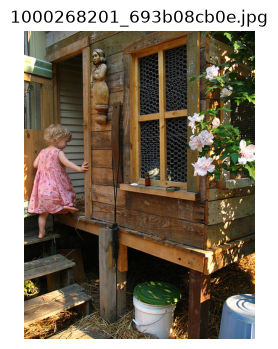

raw:   A child in a pink dress is climbing up a set of stairs in an entry way .
clean: startseq a child in a pink dress is climbing up a set of stairs in an entry way endseq

raw:   A girl going into a wooden building .
clean: startseq a girl going into a wooden building endseq

raw:   A little girl climbing into a wooden playhouse .
clean: startseq a little girl climbing into a wooden playhouse endseq

raw:   A little girl climbing the stairs to her playhouse .
clean: startseq a little girl climbing the stairs to her playhouse endseq

raw:   A little girl in a pink dress going into a wooden cabin .
clean: startseq a little girl in a pink dress going into a wooden cabin endseq



In [5]:
example_id = "1000268201_693b08cb0e.jpg"

plt.figure(figsize=(5, 4))
plt.imshow(Image.open(images_dir / example_id))
plt.title(example_id); plt.axis("off"); plt.show()

for raw, clean in zip(raw_captions[example_id], data.captions[example_id]):
    print(f"raw:   {raw}\nclean: {clean}\n")

## 3. Train / validation / test split

The split is done on **unique image IDs**, so all 5 captions of a photo stay in one split. If captions were split individually, the same photo could be seen in training and again at test time, which would inflate BLEU scores (data leakage).

In [6]:
for name, ids in data.splits.items():
    print(f"{name:5s}: {len(ids):5,} images, {5 * len(ids):6,} captions")

train, val, test = (set(data.splits[k]) for k in ("train", "val", "test"))
print("\ntrain & val:", len(train & val), " train & test:", len(train & test), " val & test:", len(val & test))
print("all images covered:", train | val | test == set(data.captions))
print("reproducible (re-run gives same split):", prepare_flickr8k(seed=42).splits == data.splits)

train: 6,472 images, 32,360 captions
val  :   809 images,  4,045 captions
test :   810 images,  4,050 captions

train & val: 0  train & test: 0  val & test: 0
all images covered: True


reproducible (re-run gives same split): True


## 4. Tokenizer (fitted on training captions only)

In [7]:
tok = data.tokenizer
print("Vocabulary size (incl. padding 0 and <unk>):", data.vocab_size)
print("Max caption length (train, incl. start/end):", data.max_length)
print("startseq ->", tok.word_index["startseq"], "| endseq ->", tok.word_index["endseq"],
      "|", OOV_TOKEN, "->", tok.word_index[OOV_TOKEN])
print("Most frequent words:", list(tok.word_index)[1:11])

# Words in val/test that the model never saw in training become <unk>.
for split in ("val", "test"):
    caps = [c for cs in data.split_captions(split).values() for c in cs]
    seqs = tok.texts_to_sequences(caps)
    n_tokens = sum(len(s) for s in seqs)
    n_unk = sum(s.count(1) for s in seqs)
    print(f"{split}: {n_unk} of {n_tokens:,} tokens are <unk> ({100 * n_unk / n_tokens:.2f}%)")

Vocabulary size (incl. padding 0 and <unk>): 7702
Max caption length (train, incl. start/end): 39
startseq -> 4 | endseq -> 3 | <unk> -> 1
Most frequent words: ['a', 'endseq', 'startseq', 'in', 'the', 'on', 'is', 'and', 'dog', 'with']
val: 479 of 52,027 tokens are <unk> (0.92%)
test: 461 of 52,179 tokens are <unk> (0.88%)


## 5. Next-word training sequences

Each caption becomes several (input prefix → next word) pairs. In `create_sequences`, `seq[:i]` is the input prefix and `seq[i]` is the target word.

In [8]:
one = {example_id: [data.captions[example_id][1]]}
ids, X_ex, y_ex = create_sequences(one, tok, data.max_length)
print("Caption:", one[example_id][0], "\n")
for prefix, target in zip(tok.sequences_to_texts(X_ex), y_ex):
    print(f"{prefix:45s} -> {tok.index_word[int(target)]}")
print("\nLast padded input row (pre-padded with 0):\n", X_ex[-1])

Caption: startseq a girl going into a wooden building endseq 

startseq                                      -> a
startseq a                                    -> girl
startseq a girl                               -> going
startseq a girl going                         -> into
startseq a girl going into                    -> a
startseq a girl going into a                  -> wooden
startseq a girl going into a wooden           -> building
startseq a girl going into a wooden building  -> endseq

Last padded input row (pre-padded with 0):
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   4   2  20 319  64
   2 195 122]


In [9]:
train_ids, X_train, y_train = create_sequences(data.split_captions("train"), tok, data.max_length)
val_ids, X_val, y_val = create_sequences(data.split_captions("val"), tok, data.max_length)

print("train: image_ids", train_ids.shape, "| X", X_train.shape, X_train.dtype, "| y", y_train.shape, y_train.dtype)
print("val:   image_ids", val_ids.shape, "| X", X_val.shape, X_val.dtype, "| y", y_val.shape, y_val.dtype)
print(f"X_train memory: {X_train.nbytes / 1e6:.1f} MB")
print("targets within vocabulary:", 0 < y_train.min() and y_train.max() < data.vocab_size)

train: image_ids (381317,) | X (381317, 39) int32 | y (381317,) int32
val:   image_ids (47982,) | X (47982, 39) int32 | y (47982,) int32
X_train memory: 59.5 MB
targets within vocabulary: True


`image_ids` links each pair to its photo. In the next task, the 4,096-d VGG16 feature for `image_ids[k]` will be looked up per batch, instead of copying it ~59 times per image (which would need ~6 GB for the training set alone).

## 6. Save outputs for the next tasks

In [10]:
out_dir = PROJECT_ROOT / "data" / "processed"
data.save(out_dir)
print("Saved:", sorted(p.name for p in out_dir.iterdir()))

Saved: ['metadata.json', 'splits.json', 'tokenizer.json']
